In [39]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# =====================================================
# 0. 期刊通用出版级样式设定 (与前图保持完全一致)
# =====================================================
def set_paper_style():
    plt.rcParams.update({
        "font.family": "serif", 
        "font.serif": ["Times New Roman"], 
        "mathtext.fontset": "stix",
        "pdf.fonttype": 42, 
        "ps.fonttype": 42,
        "axes.labelsize": 14, 
        "xtick.labelsize": 12, 
        "ytick.labelsize": 12,
        "legend.fontsize": 10.5, 
        "axes.linewidth": 1.1,
        "xtick.direction": "in", 
        "ytick.direction": "in", 
        "xtick.top": True, 
        "ytick.right": True,
        "xtick.major.size": 5.0, 
        "ytick.major.size": 5.0,
        "xtick.minor.size": 2.5, 
        "ytick.minor.size": 2.5,
        "xtick.major.width": 1.0, 
        "ytick.major.width": 1.0,
        "figure.dpi": 300, 
        "savefig.bbox": "tight"
    })

set_paper_style()

OUT_DIR = "figs"
os.makedirs(OUT_DIR, exist_ok=True)

# =====================================================
# 1. 数据读取与年龄字段智能合并
# =====================================================
clean_key = lambda s: s.astype(str).str.lower().str.replace(' ', '', regex=False)

df = pd.read_csv("network_msr_results_871.csv")
df['key'] = clean_key(df['Name'])

# 从 Zhang 的数据表中读取绝对年龄 Age
df_zhang = pd.read_csv("../network_dgree/Zhang_data/Cluster_Analysis_Toolkit/Cluster_MSR_Tau_Data.csv")
df_zhang.columns = [c.lower().strip() for c in df_zhang.columns]
df_zhang['key'] = clean_key(df_zhang['name'])

# 智能识别年龄列 (寻找 age, logt, logage 等)
age_col = None
for c in ['age', 'logt', 'logage', 'log_age', 'age_myr']:
    if c in df_zhang.columns:
        age_col = c
        break

if age_col is not None:
    # 若以 log10(yr) 存储 (通常在 6.0 ~ 10.0 之间)，转为 Myr
    if df_zhang[age_col].median() > 5.0:
        df_zhang['age_myr'] = 10.0 ** (df_zhang[age_col] - 6.0)
    elif df_zhang[age_col].median() < 0.1:  # 若单位为 Gyr
        df_zhang['age_myr'] = df_zhang[age_col] * 1000.0
    else:  # 本身即为 Myr
        df_zhang['age_myr'] = df_zhang[age_col]
        
    df = pd.merge(df, df_zhang[['key', 'age_myr']], on='key', how='left')
else:
    # 备用方案：如果未找到绝对年龄列，使用动力学演化标度作为占位
    print("Warning: 未在张的数据表中找到直接的 age 字段，请确认列名！")
    df['age_myr'] = np.nan

# 划分四个年龄阶段箱子
# Very Young (<10 Myr), Young (10-100 Myr), Intermediate (100-1000 Myr), Old (>1000 Myr)
bins_age = [0, 10, 100, 1000, np.inf]
labels_age = ['Very Young\n(<10 Myr)', 'Young\n(10–100 Myr)', 'Intermediate\n(0.1–1 Gyr)', 'Old\n(>1 Gyr)']
df['age_group'] = pd.cut(df['age_myr'], bins=bins_age, labels=labels_age, right=False)

# 指标配置
METRICS = [
    ('dc_msr_10', r'$\mathrm{DC}_{\mathrm{MSR}}$', '#991B1B'),   # 深赤红
    ('cl_msr_10', r'$\mathrm{CL}_{\mathrm{MSR}}$', '#7C3AED'),   # 丁香紫
    ('bc_msr_10', r'$\mathrm{BC}_{\mathrm{MSR}}$', '#2563EB')    # 典雅蓝
]

# =====================================================
# 图 1: 三个中心指标 vs Lambda3D_5 (对应截图 2)
# =====================================================
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))

for ax, (key, label, color) in zip(axes, METRICS):
    sub = df.dropna(subset=[key, 'lambda3d_5'])
    r, p = spearmanr(sub['lambda3d_5'], sub[key])
    
    # 散点
    ax.scatter(sub['lambda3d_5'], sub[key], s=9, alpha=0.45, 
               c=color, edgecolors='none', marker='o')
    
    # 参考基准虚线 (1.0 无分聚)
    ax.axvline(1.0, color='#64748B', ls='--', lw=0.9, alpha=0.7)
    ax.axhline(1.0, color='#64748B', ls='--', lw=0.9, alpha=0.7)
    
    ax.set_xlabel(r'$\Lambda_{\mathrm{MSR, 3D}}$')
    ax.set_ylabel(label)
    
    # 顶部统计标注 (精确对齐截图 2)
    p_str = f"{p:.1e}".replace('e-0', r'\times 10^{-').replace('e-', r'\times 10^{-') + '}' if p < 0.001 else f"{p:.3f}"
    ax.set_title(rf"$\rho = {r:.3f}\ (p = {p_str})$", pad=7, fontsize=12.5)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/Fig1_MSR_vs_Lambda.pdf')
plt.close()

# =====================================================
# 图 2: 所有 MSR 指标 vs log10(tau) 演化 (对应截图 1 的 Figure 3)
# =====================================================
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)

# 分箱计算中位数与四分位误差 (16th ~ 84th 百分位)
tau_bins = np.linspace(-2.2, 0.0, 9)
tau_centers = 0.5 * (tau_bins[:-1] + tau_bins[1:])

for ax, (key, label, color) in zip(axes, METRICS):
    sub = df.dropna(subset=[key, 'lambda3d_5', 'log_tau'])
    
    # 1. 背景微散点
    ax.scatter(sub['log_tau'], sub['lambda3d_5'], s=5, alpha=0.20, c='#1E3A8A', label=r'$\Lambda_{\mathrm{MSR, 3D}}$')
    ax.scatter(sub['log_tau'], sub[key], s=5, alpha=0.22, c=color, label=label)
    
    # 2. 计算分箱统计量
    med_lam, err_lam = [], [[], []]
    med_net, err_net = [], [[], []]
    
    for i in range(len(tau_bins) - 1):
        cond = (sub['log_tau'] >= tau_bins[i]) & (sub['log_tau'] < tau_bins[i+1])
        b_data = sub[cond]
        if len(b_data) > 0:
            # Lambda3D
            m_l = b_data['lambda3d_5'].median()
            q16_l, q84_l = np.percentile(b_data['lambda3d_5'], [25, 75])
            med_lam.append(m_l)
            err_lam[0].append(max(0, m_l - q16_l))
            err_lam[1].append(max(0, q84_l - m_l))
            
            # Network MSR
            m_n = b_data[key].median()
            q16_n, q84_n = np.percentile(b_data[key], [25, 75])
            med_net.append(m_n)
            err_net[0].append(max(0, m_n - q16_n))
            err_net[1].append(max(0, q84_n - m_n))
        else:
            med_lam.append(np.nan); err_lam[0].append(0); err_lam[1].append(0)
            med_net.append(np.nan); err_net[0].append(0); err_net[1].append(0)
            
    # 3. 绘制带有误差棒的中位数趋势线
    ax.errorbar(tau_centers, med_lam, yerr=err_lam, fmt='-o', color='#1E3A8A', 
                lw=1.6, ms=4, capsize=3, capthick=1.0, label=r'Median $\Lambda_{\mathrm{MSR, 3D}}$', zorder=4)
    ax.errorbar(tau_centers, med_net, yerr=err_net, fmt='-s', color=color, 
                lw=1.6, ms=4, capsize=3, capthick=1.0, label=rf'Median {label}', zorder=5)
    
    # 水平参考虚线
    ax.axhline(1.0, color='#64748B', ls='--', lw=0.9, alpha=0.7)
    
    ax.set_xlabel(r'$\log_{10}(\tau)$')
    ax.set_xlim(-2.3, 0.1)
    ax.set_ylim(-0.1, 3.8)
    ax.legend(loc='upper right', frameon=False, fontsize=8.8)

axes[0].set_ylabel(r'$\Lambda_{\mathrm{MSR}}$')

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/Fig2_all_MSR_vs_tau.pdf')
plt.close()

# =====================================================
# 图 3: 三个中心指标对绝对物理年龄组 (Age Bins) 的箱线图
# =====================================================
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=False)

for ax, (key, label, color) in zip(axes, METRICS):
    sub = df.dropna(subset=[key, 'age_group'])
    grouped_data = [sub[sub['age_group'] == grp][key].values for grp in labels_age]
    
    # 绘制箱体
    box = ax.boxplot(
        grouped_data, 
        patch_artist=True, 
        widths=0.48,
        notch=False,
        showmeans=True,
        meanprops=dict(marker='o', markeredgecolor='black', markerfacecolor='white', markersize=4.5),
        medianprops=dict(color='#0F172A', lw=1.4),
        whiskerprops=dict(color='#475569', lw=1.1),
        capprops=dict(color='#475569', lw=1.1),
        flierprops=dict(marker='.', markersize=4, markerfacecolor='#94A3B8', markeredgecolor='none', alpha=0.5)
    )
    
    # 统一给箱体上淡色
    for patch in box['boxes']:
        patch.set_facecolor(color)
        patch.set_alpha(0.35)
        patch.set_edgecolor(color)
        patch.set_linewidth(1.2)
        
    # 水平无分聚参考线
    ax.axhline(1.0, color='#64748B', ls='--', lw=0.9, alpha=0.7)
    
    ax.set_xticklabels(labels_age, fontsize=10.5)
    ax.set_ylabel(label)
    
    # 标注各箱子的星团数量 N
    counts = [len(v) for v in grouped_data]
    for idx, count in enumerate(counts):
        ax.text(idx + 1, ax.get_ylim()[1] * 0.94, f"$N={count}$", 
                ha='center', va='top', fontsize=9.5, color='#475569')

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/Fig3_MSR_vs_Age_Bins.pdf')
plt.close()

print(f"优化完成！全部图表已输出至 '{OUT_DIR}/' 目录：")
print("1. Fig1_MSR_vs_Lambda.pdf")
print("2. Fig2_all_MSR_vs_tau.pdf")
print("3. Fig3_MSR_vs_Age_Bins.pdf")

优化完成！全部图表已输出至 'figs/' 目录：
1. Fig1_MSR_vs_Lambda.pdf
2. Fig2_all_MSR_vs_tau.pdf
3. Fig3_MSR_vs_Age_Bins.pdf


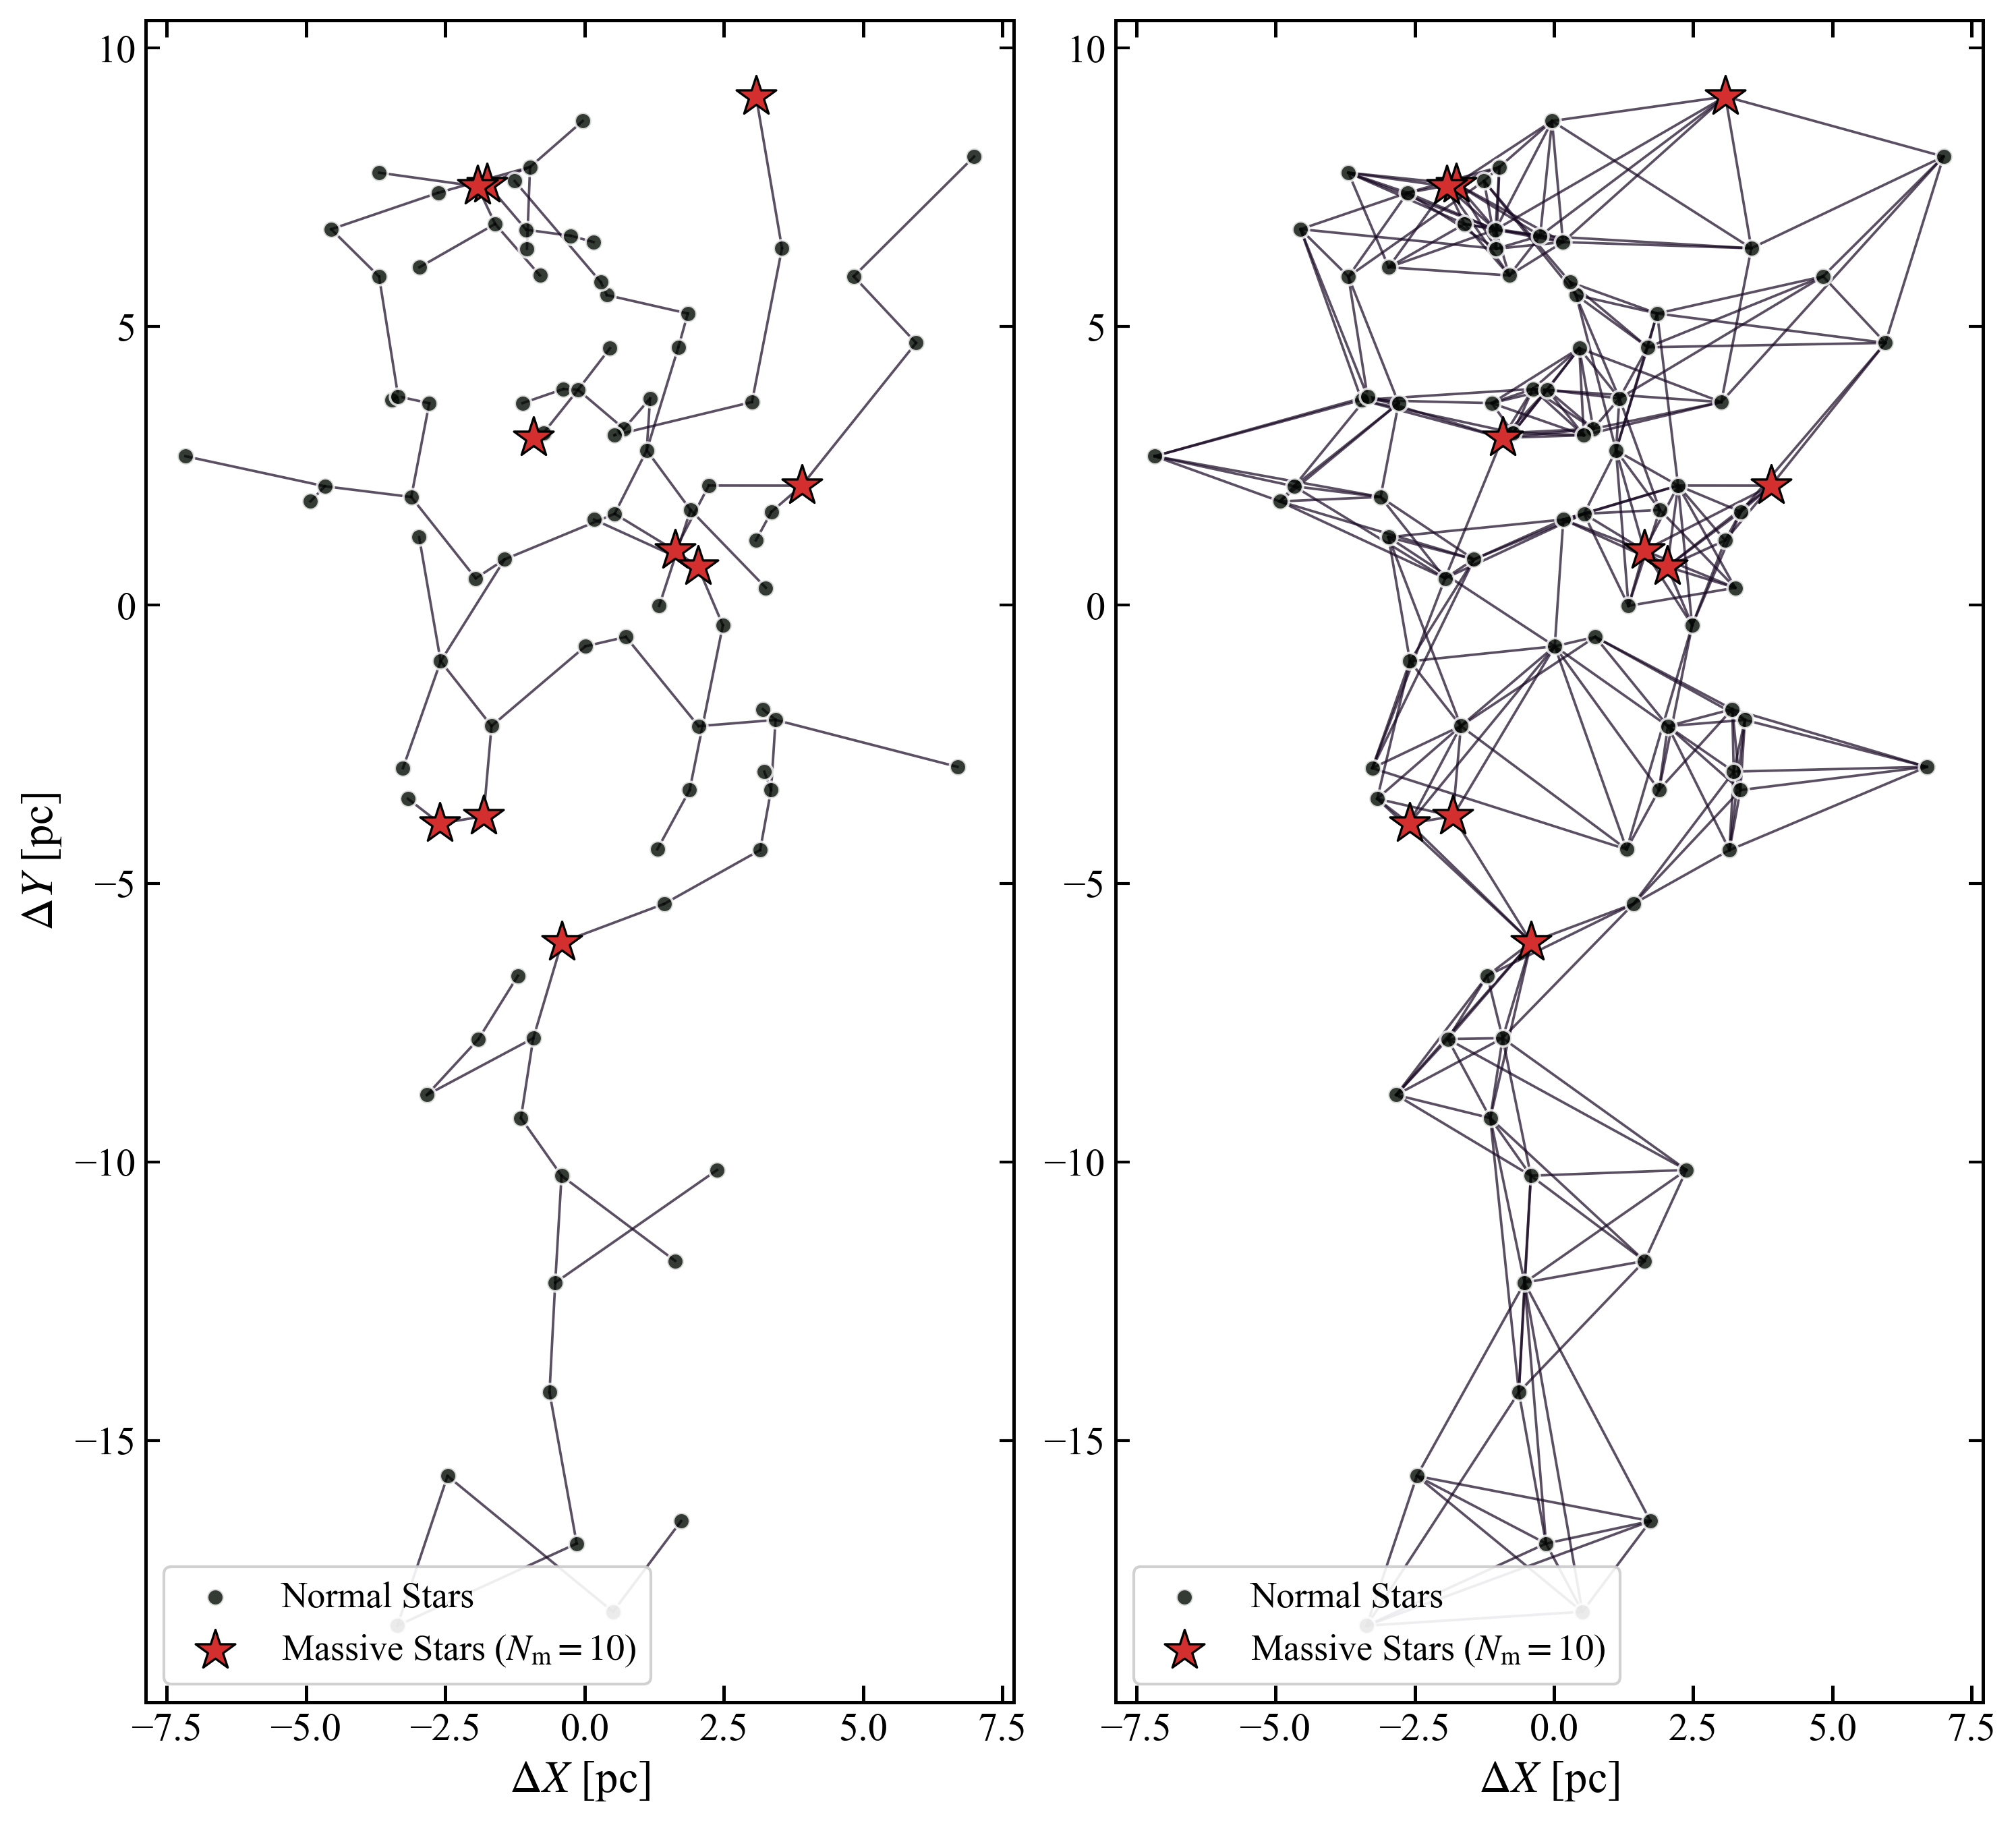

In [37]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.neighbors import kneighbors_graph
from scipy.spatial.distance import pdist, squareform

def set_paper_style():
    plt.rcParams.update({
        "font.family": "serif", "font.serif": ["Times New Roman"], "mathtext.fontset": "stix",
        "pdf.fonttype": 42, "ps.fonttype": 42,
        "axes.labelsize": 16, "axes.titlesize": 16, "xtick.labelsize": 14, "ytick.labelsize": 14,
        "legend.fontsize": 13, "axes.linewidth": 1.2,
        "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
        "xtick.major.size": 6.0, "ytick.minor.size": 3.0,
        "xtick.major.width": 1.2, "figure.dpi": 300, "savefig.bbox": "tight"
    })

set_paper_style()

# 1. 数据准备
df_raw = pd.read_csv("../network_dgree/Zhang_data/hunt24/OC_0479.csv")
df_raw = df_raw[df_raw['Prob'] >= 0.8].dropna(subset=['RAdeg', 'DEdeg', 'Plx', 'Mass50']).sort_values('Mass50', ascending=False)

N_massive = 10
n_sample = min(len(df_raw) - N_massive, 90)
df_m = pd.concat([df_raw.iloc[:N_massive], df_raw.iloc[N_massive:].sample(n_sample, random_state=42)]).reset_index(drop=True)

ra, dec = np.radians(df_m['RAdeg']), np.radians(df_m['DEdeg'])
d = 1000.0 / df_m['Plx']
coords = np.column_stack([d * np.cos(dec) * np.cos(ra), d * np.cos(dec) * np.sin(ra), d * np.sin(dec)])
coords -= coords.mean(axis=0)
x, y = coords[:, 0], coords[:, 1]

mas_idx = np.arange(N_massive)
norm_idx = np.arange(N_massive, len(df_m))

# 2. 两个网络的完整图构建
G_mst = nx.minimum_spanning_tree(nx.from_numpy_array(squareform(pdist(coords))))
G_knn = nx.from_scipy_sparse_array(kneighbors_graph(coords, n_neighbors=5, mode='distance', include_self=False))

# 3. 绘图
fig, axes = plt.subplots(1, 2, figsize=(10, 10))
# titles = [r"Minimum Spanning Tree (MST)", r"$K$-Nearest Neighbors (KNN, $K=5$)"]

for ax, G, title in zip(axes, [G_mst, G_knn], titles):
    ax.set(aspect='equal', xlabel=r"$\Delta X$ [pc]")
    # ax.set_title(title, pad=15, fontweight='bold')
    
    # 绘制网络连边
    for u, v in G.edges():
        ax.plot([x[u], x[v]], [y[u], y[v]], color="#16062197", lw=0.9, alpha=0.7, zorder=1)
        
    # 绘制节点：普通星 vs 大质量星
    ax.scatter(x[norm_idx], y[norm_idx], s=35, c="#010801", edgecolors='white', lw=0.9, alpha=0.8, zorder=2, label='Normal Stars')
    ax.scatter(x[mas_idx], y[mas_idx], s=220, c='#D32F2F', marker='*', edgecolors='k', lw=0.8, zorder=3, label=r'Massive Stars ($N_{\rm m}=10$)')
    ax.legend(loc='lower left', frameon=True, framealpha=0.9)

axes[0].set_ylabel(r"$\Delta Y$ [pc]")

# 保证左右子图坐标尺度完全锁死一致
# axes[1].set_xlim(axes[0].get_xlim())
# axes[1].set_ylim(axes[0].get_ylim())

plt.tight_layout()
plt.savefig('../network_dgree/figs/network.pdf', dpi=300, bbox_inches='tight')
plt.show()

Evaluating k-robustness: 100%|██████████| 871/871 [05:34<00:00,  2.60it/s]  


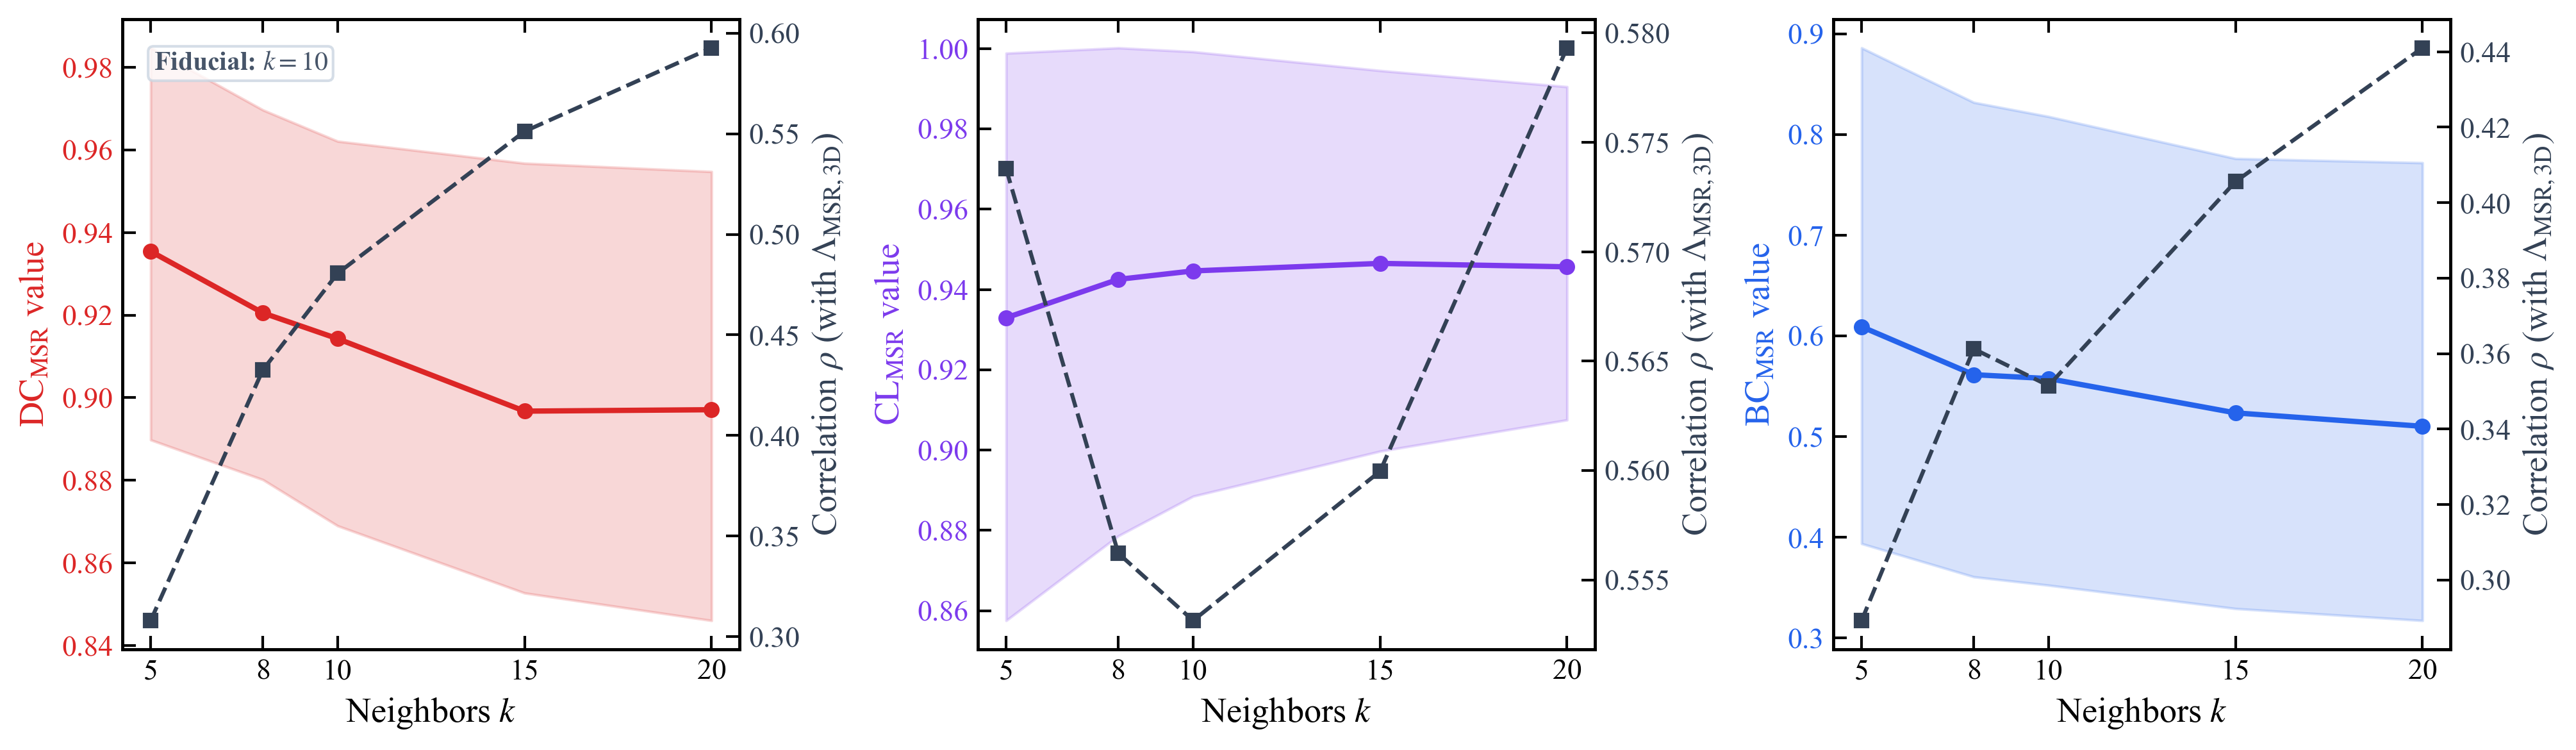

In [41]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.neighbors import kneighbors_graph
from tqdm import tqdm

# --- 1. 出版级样式与参数 ---
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman"], "mathtext.fontset": "stix",
    "pdf.fonttype": 42, "axes.labelsize": 13, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "legend.fontsize": 10, "axes.linewidth": 1.1, "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True, "figure.dpi": 300, "savefig.bbox": "tight"
})

DATA_DIR = "../network_dgree/Zhang_data"
K_LIST = [5, 8, 10, 15, 20]     # 稳健性检验的 k 邻居数范围
N_M = 10                        # 基准窗口 (Top 10 大质量星)

# --- 2. 读入数据与坐标构建 ---
df_meta = pd.read_csv(f"{DATA_DIR}/hunt24.csv").rename(columns=lambda c: c.lower().strip())
df_tau = pd.read_csv(f"{DATA_DIR}/Cluster_Analysis_Toolkit/Cluster_MSR_Tau_Data.csv").rename(columns=lambda c: c.lower().strip())
df_meta['key'], df_tau['key'] = df_meta['name'].str.lower().str.replace(' ', ''), df_tau['name'].str.lower().str.replace(' ', '')
meta = df_meta.set_index('key').to_dict('index')

def get_xyz(m, p_cl, s_cl):
    ra, dec = np.radians(m['radeg']), np.radians(m['dedeg'])
    s_s2, s_c2 = m['e_plx']**2, max(s_cl, 0.01)**2
    d = 1000.0 / ((m['plx']*s_c2 + p_cl*s_s2) / (s_c2 + s_s2))
    xyz = np.column_stack([d*np.cos(dec)*np.cos(ra), d*np.cos(dec)*np.sin(ra), d*np.sin(dec)])
    return xyz - xyz.mean(axis=0)

# --- 3. 循环计算不同 k 值的 MSR ---
records = []
for _, row in tqdm(df_tau.iterrows(), total=len(df_tau), desc="Evaluating k-robustness"):
    k_name = row['key']
    fpath = f"{DATA_DIR}/hunt24/{k_name}.csv"
    if not os.path.exists(fpath) or k_name not in meta:
        continue
    m = pd.read_csv(fpath).rename(columns=lambda c: c.lower().strip()).dropna(subset=['prob', 'mass50', 'radeg', 'dedeg', 'plx', 'e_plx'])
    m = m[m['prob'] >= 0.8]
    if not (25 <= len(m) <= 1500):
        continue
        
    xyz = get_xyz(m, meta[k_name]['plx'], meta[k_name].get('e_plx', 0.05))
    top_idx = np.argsort(m['mass50'].values)[-N_M:]
    
    # 针对不同 k 分别建图计算
    for k in K_LIST:
        G = nx.from_scipy_sparse_array(kneighbors_graph(xyz, n_neighbors=k, mode='distance', include_self=False))
        dc = np.fromiter(nx.degree_centrality(G).values(), float)
        cl = np.fromiter(nx.closeness_centrality(G).values(), float)
        bc = np.fromiter(nx.betweenness_centrality(G, weight='weight').values(), float)
        
        records.append({
            'k': k, 'lambda': row.get('lambda3d_5', np.nan),
            'dc': np.mean(dc[top_idx] / np.mean(dc)),
            'cl': np.mean(cl[top_idx] / np.mean(cl)),
            'bc': np.mean(bc[top_idx] / (np.mean(bc) + 1e-9))
        })

df_k = pd.DataFrame(records).dropna(subset=['lambda'])

# --- 4. 稳健性一键出图 (3 Panel: DC, CL, BC) ---
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), sharex=True)
metrics = [('dc', r'$\mathrm{DC}_{\mathrm{MSR}}$', '#DC2626'), 
           ('cl', r'$\mathrm{CL}_{\mathrm{MSR}}$', '#7C3AED'), 
           ('bc', r'$\mathrm{BC}_{\mathrm{MSR}}$', '#2563EB')]

for ax, (m_key, label, col) in zip(axes, metrics):
    ax2 = ax.twinx()  # 右轴绘制相关系数 rho
    
    meds, q25s, q75s, rhos = [], [], [], []
    for k in K_LIST:
        sub = df_k[df_k['k'] == k]
        meds.append(sub[m_key].median())
        q25s.append(np.percentile(sub[m_key], 25))
        q75s.append(np.percentile(sub[m_key], 75))
        rhos.append(spearmanr(sub[m_key], sub['lambda'])[0])
    
    # 左轴：MSR 中位数及四分位带 (实线 + 阴影)
    # ax.axhline(1.0, color='#94A3B8', ls='--', lw=0.9, zorder=1)
    ax.plot(K_LIST, meds, '-o', color=col, lw=2.0, ms=5, label='Median MSR')
    ax.fill_between(K_LIST, q25s, q75s, color=col, alpha=0.18)
    
    # 右轴：与 Lambda 的 Spearman rho (深灰虚线 + 方块)
    ax2.plot(K_LIST, rhos, '--s', color='#334155', lw=1.5, ms=5, label=r'Spearman $\rho$')
    
    # 标出基准值 (比如 k=10)
    # ax.axvline(10, color='#64748B', ls=':', lw=1.2, alpha=0.8)
    
    ax.set_xlabel(r'Neighbors $k$')
    ax.set_ylabel(f'{label} value', color=col)
    ax2.set_ylabel(r'Correlation $\rho$ (with $\Lambda_{\mathrm{MSR, 3D}}$)', color='#334155')
    ax.tick_params(axis='y', labelcolor=col)
    ax2.tick_params(axis='y', labelcolor='#334155')
    ax.set_xticks(K_LIST)

axes[0].text(0.05, 0.92, 'Fiducial: $k=10$', transform=axes[0].transAxes, fontsize=10, 
            fontweight='bold', color='#475569', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#CBD5E1', alpha=0.8))

plt.tight_layout()
os.makedirs("figs", exist_ok=True)
plt.savefig("figs/robustness_k.pdf")
plt.show()